This notebook is for exploring the dataset, finding problems that needs to be fixed. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_excel('../Data/raw/online_retail_II.xlsx')
df.shape

(525461, 8)

Only reading one sheet, file has two

In [3]:
sheet = pd.read_excel('../Data/raw/online_retail_II.xlsx', sheet_name =None)

In [4]:
sheet.keys()

dict_keys(['Year 2009-2010', 'Year 2010-2011'])

In [5]:
df = pd.concat(sheet.values(), ignore_index = True)
df.shape

(1067371, 8)

In [6]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [8]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


negative values = return/canellations
checking to see how much of the data is returns/cansellations


In [9]:
neg = df[df['Quantity'] < 0]
neg.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [10]:
is_cancelled = df['Invoice'].astype(str).str.startswith('C')
print(is_cancelled.sum())

19494


The table under seems to be the stores own regulation of products, maybe broken or lost products in storage. 

In [11]:
df[(df["Quantity"] < 0) & ~is_cancelled].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom


For now using the date from sales, not returns. Maybe returns could be good nect project. 

In [12]:
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)].copy()


In [13]:
df['Revenue'] = df['Quantity']*df['Price']

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 1041671 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1041671 non-null  object        
 1   StockCode    1041671 non-null  object        
 2   Description  1041671 non-null  object        
 3   Quantity     1041671 non-null  int64         
 4   InvoiceDate  1041671 non-null  datetime64[us]
 5   Price        1041671 non-null  float64       
 6   Customer ID  805549 non-null   float64       
 7   Country      1041671 non-null  str           
 8   Revenue      1041671 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 79.5+ MB


In [15]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID,Revenue
count,1.041671e+06,1041671,1.041671e+06,805549.000000,1.041671e+06
mean,1.096345e+01,2011-01-03 16:31:26.403269,4.077038e+00,15331.954970,2.013397e+01
min,1.000000e+00,2009-12-01 07:45:00,1.000000e-03,12346.000000,1.000000e-03
25%,1.000000e+00,2010-07-12 10:26:00,1.250000e+00,13982.000000,3.900000e+00
50%,3.000000e+00,2010-12-07 15:33:00,2.100000e+00,15271.000000,9.960000e+00
75%,1.000000e+01,2011-07-24 12:05:00,4.130000e+00,16805.000000,1.770000e+01
max,8.099500e+04,2011-12-09 12:50:00,2.511109e+04,18287.000000,1.684696e+05
std,1.265149e+02,NaN,5.144898e+01,1696.737039,2.031167e+02


<Axes: xlabel='InvoiceDate'>

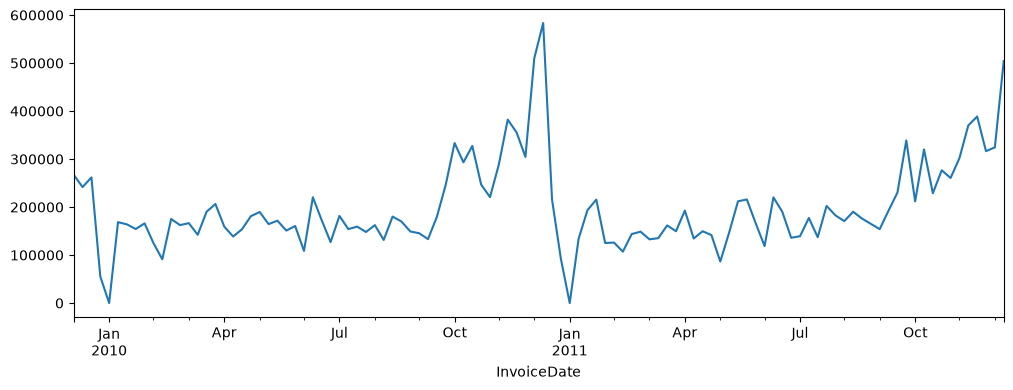

In [16]:
df.set_index('InvoiceDate')["Revenue"].resample("W").sum().plot(figsize=(12, 4))


In [20]:
df['Weekday'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

<Axes: xlabel='Hour', ylabel='Weekday'>

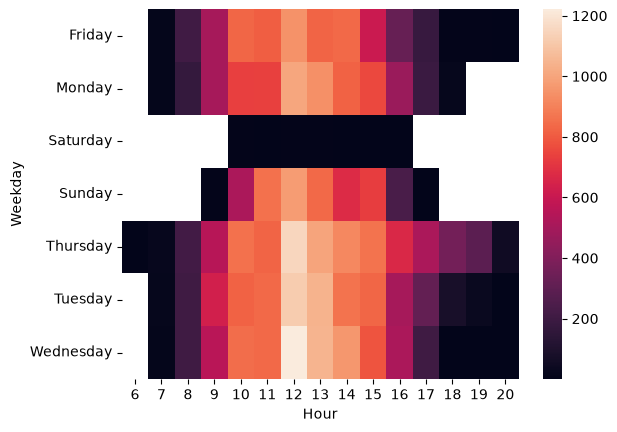

In [23]:
pivot = df.pivot_table(index="Weekday", columns="Hour", values="Invoice", aggfunc="nunique")
sns.heatmap(pivot)

seems to be more shopping between 10 and 15, and no shopping on saturday

<Axes: xlabel='Quantity', ylabel='Count'>

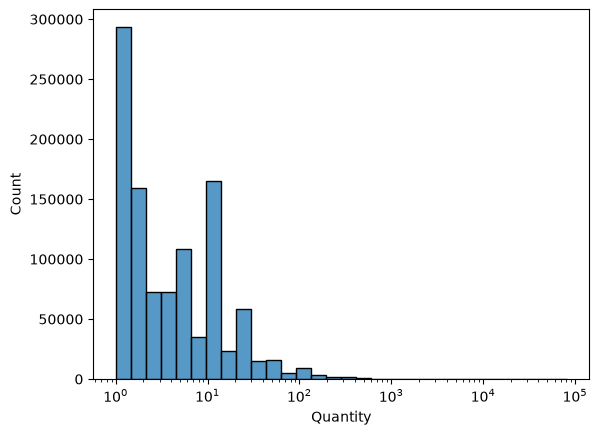

In [30]:
sns.histplot(df['Quantity'], log_scale= True, bins = 30)

<Axes: xlabel='Price', ylabel='Count'>

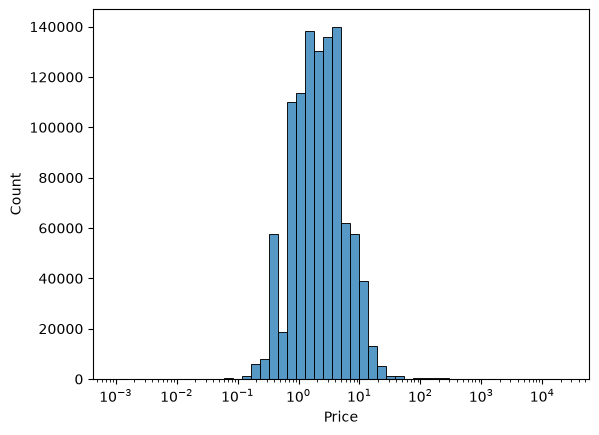

In [36]:
sns.histplot(df['Price'], log_scale = True, bins = 50)

<class 'pandas.DataFrame'>
Index: 1041671 entries, 0 to 1067370
Data columns (total 12 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1041671 non-null  object        
 1   StockCode    1041671 non-null  object        
 2   Description  1041671 non-null  object        
 3   Quantity     1041671 non-null  int64         
 4   InvoiceDate  1041671 non-null  datetime64[us]
 5   Price        1041671 non-null  float64       
 6   Customer ID  805549 non-null   float64       
 7   Country      1041671 non-null  str           
 8   Revenue      1041671 non-null  float64       
 9   Weekday      1041671 non-null  str           
 10  Time         1041671 non-null  int32         
 11  Hour         1041671 non-null  int32         
dtypes: datetime64[us](1), float64(3), int32(2), int64(1), object(3), str(2)
memory usage: 95.4+ MB


,Quantity,InvoiceDate,Price,Customer ID,Revenue,Time,Hour
count,1.041671e+06,1041671,1.041671e+06,805549.000000,1.041671e+06,1.041671e+06,1.041671e+06
mean,1.096345e+01,2011-01-03 16:31:26.403269,4.077038e+00,15331.954970,2.013397e+01,1.302858e+01,1.302858e+01
min,1.000000e+00,2009-12-01 07:45:00,1.000000e-03,12346.000000,1.000000e-03,6.000000e+00,6.000000e+00
25%,1.000000e+00,2010-07-12 10:26:00,1.250000e+00,13982.000000,3.900000e+00,1.100000e+01,1.100000e+01
50%,3.000000e+00,2010-12-07 15:33:00,2.100000e+00,15271.000000,9.960000e+00,1.300000e+01,1.300000e+01
75%,1.000000e+01,2011-07-24 12:05:00,4.130000e+00,16805.000000,1.770000e+01,1.500000e+01,1.500000e+01
max,8.099500e+04,2011-12-09 12:50:00,2.511109e+04,18287.000000,1.684696e+05,2.000000e+01,2.000000e+01
std,1.265149e+02,NaN,5.144898e+01,1696.737039,2.031167e+02,2.429089e+00,2.429089e+00
